In [9]:
from google.colab import drive
import torch
from torchvision import datasets, transforms
from torch.utils.data import Subset

drive.mount("/content/drive")

# Original images represented as tensors in [0, 1]
eda_source = datasets.CIFAR10(
    root="/content/drive//MyDrive/DDPM/data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

# Restore saved split
saved_split = torch.load(
    "/content/drive/MyDrive/DDPM/data/cifar10_split.pt",
    map_location="cpu",
    weights_only=True
)

eda_data = Subset(
    eda_source,
    saved_split["train_indices"]
)

print("Images available for training-data EDA:", len(eda_data))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Images available for training-data EDA: 45000


# Visual inspection

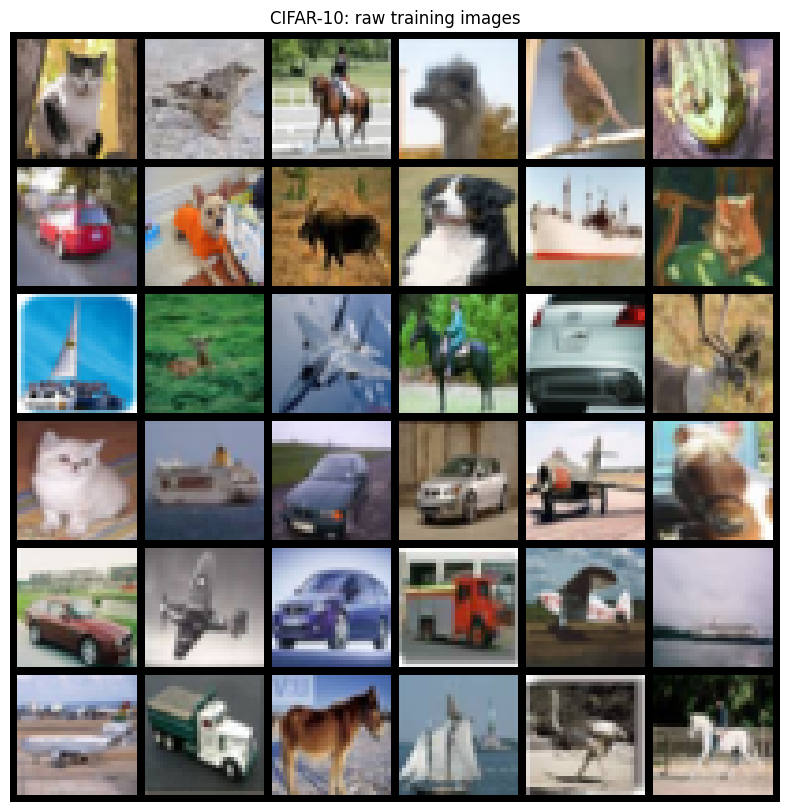

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(eda_data),
    size=36,
    replace=False
)

sample_images = torch.stack([
    eda_data[int(i)][0] for i in sample_indices
])

grid = make_grid(sample_images, nrow=6, padding=2)

plt.figure(figsize=(10, 10))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title("CIFAR-10: raw training images")
plt.axis("off")
plt.show()

# Pixel distributions before and after normalization

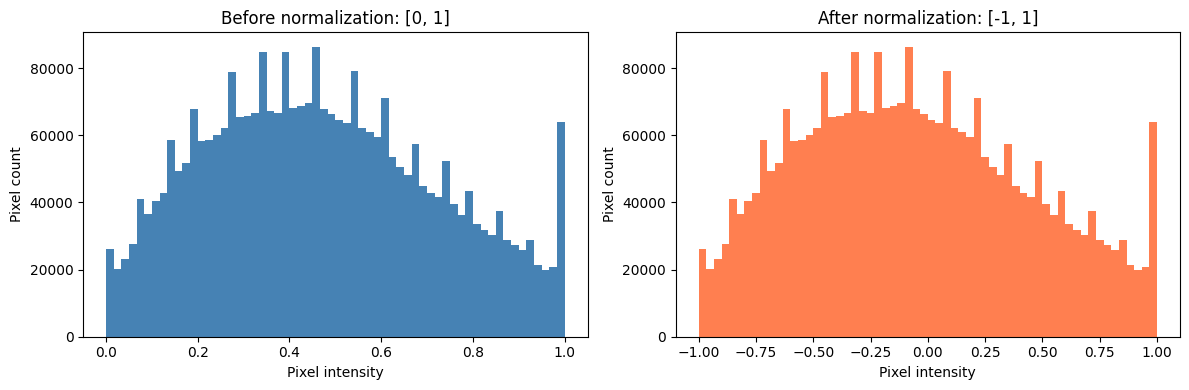

Before: 0.0 1.0
After: -1.0 1.0


In [ ]:
hist_indices = rng.choice(
    len(eda_data),
    size=min(1000, len(eda_data)),
    replace=False
)

raw_images = torch.stack([
    eda_data[int(i)][0] for i in hist_indices
])

normalized_images = raw_images * 2 - 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    raw_images.numpy().ravel(),
    bins=60,
    color="steelblue"
)
axes[0].set_title("Before normalization: [0, 1]")
axes[0].set_xlabel("Pixel intensity")

axes[1].hist(
    normalized_images.numpy().ravel(),
    bins=60,
    color="coral"
)
axes[1].set_title("After normalization: [-1, 1]")
axes[1].set_xlabel("Pixel intensity")

for ax in axes:
    ax.set_ylabel("Pixel count")

plt.tight_layout()
plt.show()

print("Before:", raw_images.min().item(), raw_images.max().item())
print(
    "After:",
    normalized_images.min().item(),
    normalized_images.max().item()
)

# Channel-wise mean and standard deviation

In [ ]:
#Computing statistics across the complete training subset without loading everything into memory.
from torch.utils.data import DataLoader

eda_loader = DataLoader(
    eda_data,
    batch_size=256,
    shuffle=False,
    num_workers=2
)

channel_sum = torch.zeros(3, dtype=torch.float64)
channel_squared_sum = torch.zeros(3, dtype=torch.float64)
pixel_count = 0

for images, _ in eda_loader:
    images = images.to(torch.float64)

    channel_sum += images.sum(dim=(0, 2, 3))
    channel_squared_sum += (images ** 2).sum(dim=(0, 2, 3))

    pixel_count += (
        images.shape[0] * images.shape[2] * images.shape[3]
    )

channel_mean = channel_sum / pixel_count

channel_variance = (
    channel_squared_sum / pixel_count
    - channel_mean ** 2
)

channel_std = channel_variance.clamp_min(0).sqrt()

for channel, mean, std in zip(
    ["Red", "Green", "Blue"],
    channel_mean,
    channel_std
):
    print(f"{channel}: mean={mean:.4f}, std={std:.4f}")

print("\nAfter [-1, 1] normalization:")
print("Mean:", channel_mean * 2 - 1)
print("Std:", channel_std * 2)

Red: mean=0.4913, std=0.2470
Green: mean=0.4822, std=0.2436
Blue: mean=0.4466, std=0.2617

After [-1, 1] normalization:
Mean: tensor([-0.0173, -0.0357, -0.1068], dtype=torch.float64)
Std: tensor([0.4941, 0.4871, 0.5234], dtype=torch.float64)


# Class balance

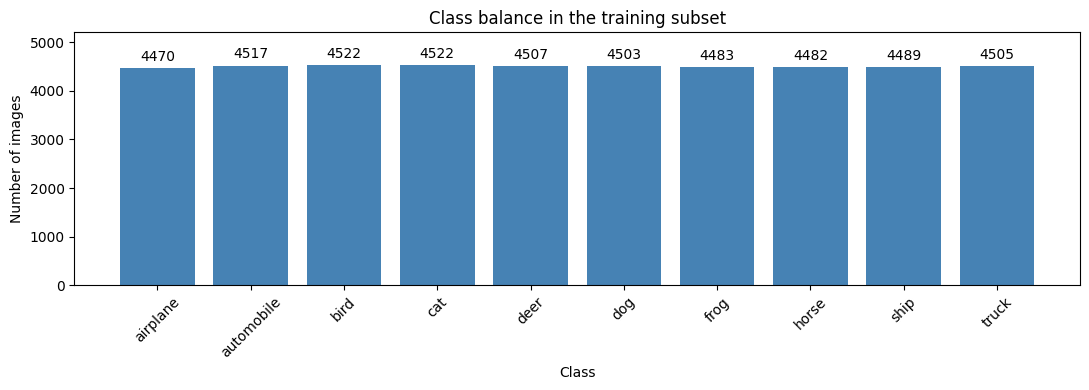

In [ ]:
training_labels = np.asarray(
    eda_source.targets
)[saved_split["train_indices"]]

class_names = eda_source.classes

counts = np.bincount(
    training_labels,
    minlength=len(class_names)
)

plt.figure(figsize=(11, 4))
bars = plt.bar(class_names, counts, color="steelblue")

plt.bar_label(bars, padding=3)
plt.title("Class balance in the training subset")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=45)
plt.ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

# Preliminary near-duplicate check

In [ ]:
from collections import defaultdict
from PIL import Image

def difference_hash(image_tensor):
    array = (
        image_tensor.permute(1, 2, 0).numpy() * 255
    ).round().clip(0, 255).astype(np.uint8)

    gray = Image.fromarray(array).convert("L").resize(
        (9, 8),
        resample=Image.Resampling.LANCZOS
    )

    pixels = np.asarray(gray)
    differences = pixels[:, 1:] > pixels[:, :-1]

    return np.packbits(differences).tobytes()


duplicate_indices = rng.choice(
    len(eda_data),
    size=min(2000, len(eda_data)),
    replace=False
)

hash_groups = defaultdict(list)

for index in duplicate_indices:
    image, _ = eda_data[int(index)]
    hash_groups[difference_hash(image)].append(int(index))

candidate_groups = [
    group for group in hash_groups.values()
    if len(group) > 1
]

print("Images checked:", len(duplicate_indices))
print("Matching-hash candidate groups:", len(candidate_groups))

# Inspect up to five candidate groups
for group in candidate_groups[:5]:
    images = torch.stack([
        eda_data[index][0] for index in group[:8]
    ])

    grid = make_grid(images, nrow=8)

    plt.figure(figsize=(10, 3))
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.title(f"Candidate group: {group[:8]}")
    plt.axis("off")
    plt.show()

Images checked: 2000
Matching-hash candidate groups: 0


This computes a difference hash for 2,000 sampled images and finds images with identical hashes. These are candidates for visual review—not confirmed duplicates or an exhaustive near-duplicate search. If no groups appear, this means no identical hashes were found in this sample, not that the dataset has no near-duplicates.

# Forward-process sanity check

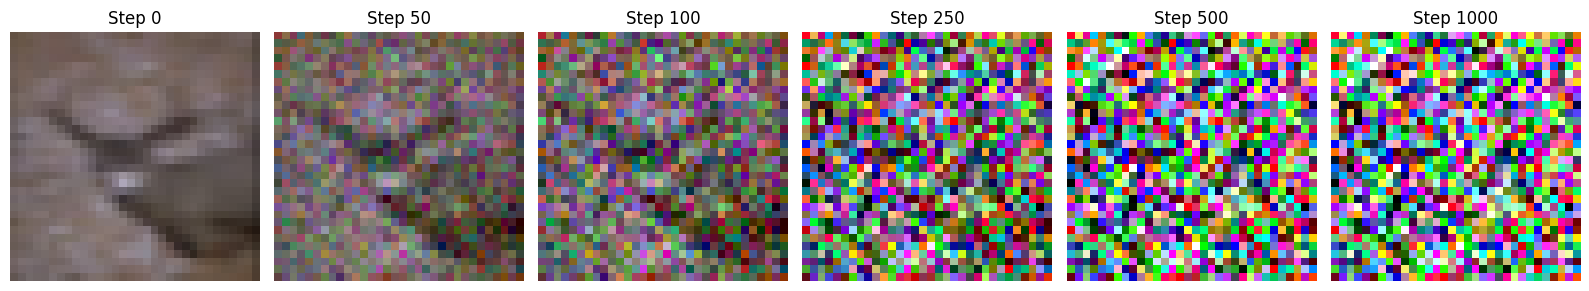

In [ ]:
# same Gaussian noise realization is used across panels to make the increasing corruption easier to compare
TIMESTEPS = 1000

betas = torch.linspace(1e-4, 0.02, TIMESTEPS)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

# Convert a raw [0, 1] image to [-1, 1]
image, _ = eda_data[0]
x0 = image * 2 - 1

noise_generator = torch.Generator().manual_seed(42)
noise = torch.randn(
    x0.shape,
    generator=noise_generator
)

steps = [0, 50, 100, 250, 500, 1000]

fig, axes = plt.subplots(1, len(steps), figsize=(16, 3))

for ax, step in zip(axes, steps):
    if step == 0:
        xt = x0
    else:
        # Schedule index 0 represents the first noise step
        alpha_bar = alpha_bars[step - 1]

        xt = (
            alpha_bar.sqrt() * x0
            + (1.0 - alpha_bar).sqrt() * noise
        )

    # Clip for display only
    display_image = ((xt + 1) / 2).clamp(0, 1)

    ax.imshow(display_image.permute(1, 2, 0).numpy())
    ax.set_title(f"Step {step}")
    ax.axis("off")

plt.tight_layout()
plt.show()